# 3 · Polarisation, 1973 to now

Each Congress from the 93rd (1973) to the 119th is fitted separately, so positions from different
Congresses are on different scales. We therefore compare only **scale-free** measures:

- **Separation:** the gap between party medians, measured in "typical party widths".
- **Overlap:** the share of members closer to the *other* party's median than their own.
- **Party-line votes:** the share of contested roll calls where most Democrats and most Republicans
  voted opposite ways, straight from the raw votes, no model.

The same separation and overlap from DW-NOMINATE serve as the known answer.

In [1]:
%matplotlib inline
import os, json, warnings
os.chdir('..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ideology import plot
plot.style()
pd.set_option('display.width', 160)

p = pd.read_csv('results/polarization.csv')
p.groupby('chamber')[['separation', 'nominate_separation']].corr().round(2)

separation  nominate_separation
chamber                                                     
H       separation                 1.00                 0.98
        nominate_separation        0.98                 1.00
S       separation                 1.00                 0.89
        nominate_separation        0.89                 1.00

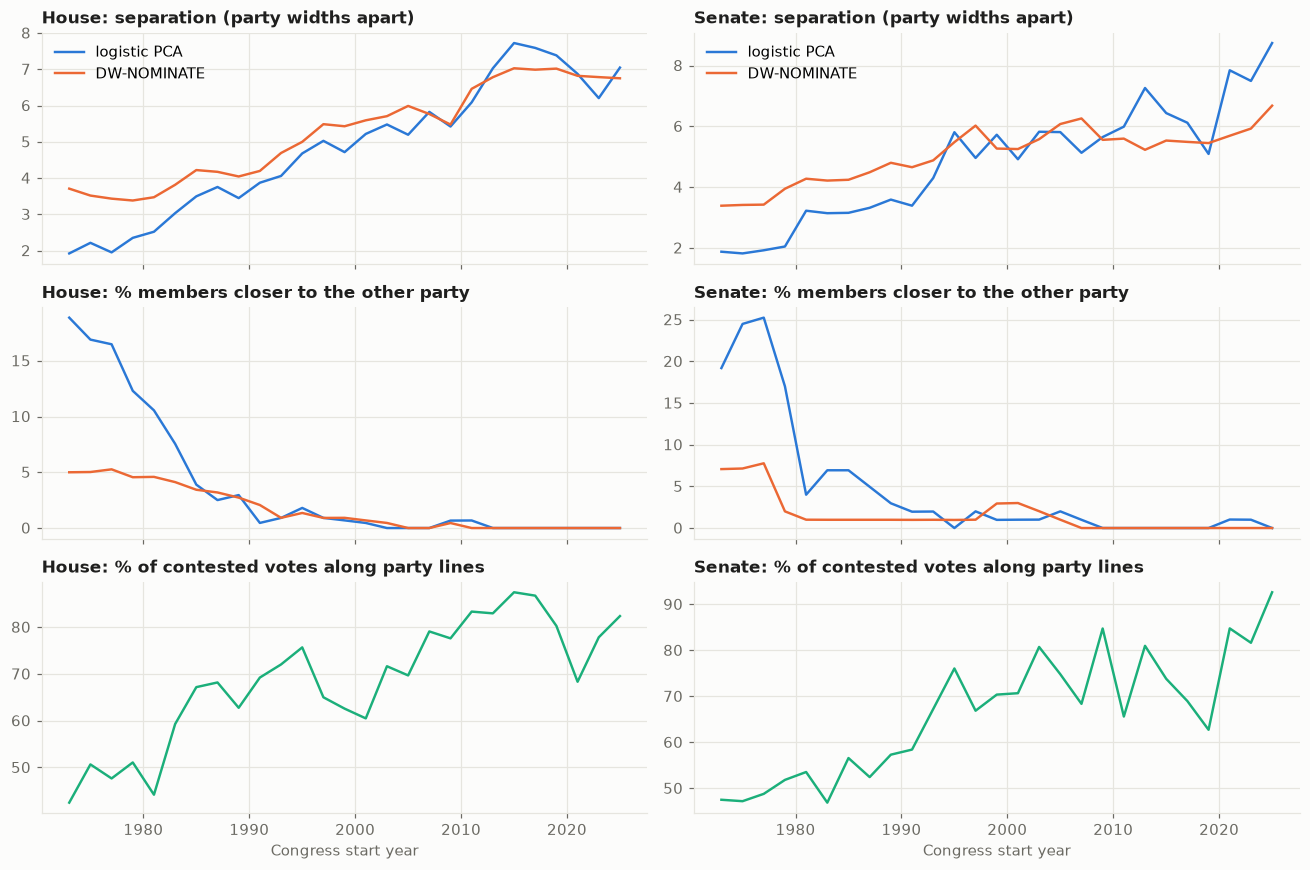

In [2]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for j, (ch, name) in enumerate((('H', 'House'), ('S', 'Senate'))):
    d = p[p.chamber == ch]
    ax = axes[0, j]
    ax.plot(d.start_year, d.separation, color=plot.SERIES[0], label='logistic PCA')
    ax.plot(d.start_year, d.nominate_separation, color=plot.SERIES[1], label='DW-NOMINATE')
    ax.set_title(f'{name}: separation (party widths apart)'); ax.legend()
    ax = axes[1, j]
    ax.plot(d.start_year, d.overlap * 100, color=plot.SERIES[0], label='logistic PCA')
    ax.plot(d.start_year, d.nominate_overlap * 100, color=plot.SERIES[1], label='DW-NOMINATE')
    ax.set_title(f'{name}: % members closer to the other party')
    ax = axes[2, j]
    ax.plot(d.start_year, d.party_line_share * 100, color=plot.SERIES[2])
    ax.set_title(f'{name}: % of contested votes along party lines')
for ax in axes[2]: ax.set_xlabel('Congress start year')
plt.tight_layout()

In [3]:
p[p.congress.isin([93, 103, 113, 119])][['chamber', 'start_year', 'separation', 'overlap', 'nominate_separation', 'nominate_overlap', 'party_line_share']].round(2)

,chamber,start_year,separation,overlap,nominate_separation,nominate_overlap,party_line_share
0,H,1973,1.92,0.19,3.71,0.05,0.42
10,H,1993,4.06,0.01,4.69,0.01,0.72
20,H,2013,7.03,0.00,6.78,0.00,0.83
26,H,2025,7.05,0.00,6.75,0.00,0.82
27,S,1973,1.88,0.19,3.39,0.07,0.48
37,S,1993,4.30,0.02,4.88,0.01,0.67
47,S,2013,7.26,0.00,5.23,0.00,0.81
53,S,2025,8.74,0.00,6.68,0.00,0.93


## What this shows

- All three measures, from two different models and from the raw votes, tell the same story: the
  parties have moved apart steadily since the 1970s.
- Overlap has vanished: since the early 2000s essentially no member is closer to the other party.
  How much overlap there was in the 1970s depends on the model: about 1 member in 5 by our
  one-dimensional fit, about 1 in 15-20 by DW-NOMINATE. That era's cross-party votes (notably
  Southern Democrats) ran partly along a second dimension, which a 1-D fit squeezes onto left-right.
- The two models' separation series track each other closely (correlation 0.98 House, 0.89 Senate).
- Party-line voting is noisier year to year (it depends on which bills reach a vote) but trends the same way.
- Absolute separation numbers differ between our model and DW-NOMINATE (different models, different
  scales); the *trend* is what agrees, and it is the trend that is reported.